# Lab 12 — AI-assisted Data Analysis & Visualization
**Dataset:** `hospital_wait_times.csv`  
**Role:** Data analyst, City General Hospital Quality Department  
**Intervention date:** July 1, 2025, Site A  

This notebook independently verifies data quality, charts, summary statistics, and the comparison between Site A and Site B. The CSV is loaded from the relative `dataset/` folder.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
D = pd.read_csv('dataset/hospital_wait_times.csv')
print('Shape:', D.shape)
D.head()

Shape: (4225, 10)


,visit_id,visit_date,site,department,triage_level,age,wait_minutes,treatment_minutes,satisfaction,triage_system
0,V103691,2025-08-17,Site B,Cardiology,4,88,52.0,28,2.0,Old
1,V100198,2025-05-04,Site A,Cardiology,5,43,87.0,75,4.0,Old
2,V104126,2025-01-17,Site A,Emergency,4,31,102.0,56,NaN,Old
3,V100202,2025-06-30,Site A,Orthopedics,2,29,17.0,98,3.0,Old
4,V104041,2025-08-26,Site A,Radiology,5,68,37.0,20,4.0,New


## Cleaning and validity rules
- Parse ISO dates and `DD/MM/YYYY` dates explicitly.
- Remove duplicate `visit_id` records (keep the first exact record).
- Exclude invalid records from outcome analyses: unparseable dates, age outside 0–120, negative waits/treatment, triage outside 1–5, or invalid site labels.
- Standardize department text variants (ER/Emergency casing and whitespace) to `Emergency`.
- Do **not** remove statistically flagged long waits automatically; flag and inspect them separately.

These choices are explicit and can affect the results; the lab manual does not fully define “valid rows.”

In [2]:
D['date'] = pd.to_datetime(D.visit_date, format='%Y-%m-%d', errors='coerce')
mask = D.date.isna()
D.loc[mask, 'date'] = pd.to_datetime(D.loc[mask, 'visit_date'], format='%d/%m/%Y', errors='coerce')
D['dept_clean'] = D.department.astype(str).str.strip().str.lower().replace({'er':'emergency'})
D['dept_clean'] = D.dept_clean.str.title().replace({'Er':'Emergency'})
valid = (~D.visit_id.duplicated()) & D.date.notna() & D.age.between(0,120) & D.wait_minutes.ge(0) & D.treatment_minutes.ge(0) & D.triage_level.between(1,5) & D.site.isin(['Site A','Site B'])
V = D[valid].copy()
V['period'] = np.where(V.date < pd.Timestamp('2025-07-01'), 'Before', 'After')
V['month'] = V.date.dt.to_period('M').astype(str)
V['wait_group'] = np.where(V.wait_minutes <= 90, '<=90', '>90')
V['age_group'] = pd.cut(V.age, bins=[-1,17,39,64,120], labels=['0-17','18-39','40-64','65+'])
V.shape, (len(D)-len(V)), D.visit_id.duplicated().sum()

((4184, 16), 41, np.int64(25))

## Task 1 — Can we trust this data?

**Answer:** “Mostly complete” is not the same as reliable. Satisfaction is missing in 517/4,225 rows (12.24%); there are 25 repeated `visit_id`s, 10 negative waits, 6 ages outside 0–120, and inconsistent department labels. Dates include mixed formats, though the explicit parser can handle them. 

**Improved prompt:** *Audit this CSV without modifying it. Report row count, duplicate visit IDs and exact duplicate rows, missingness by column, invalid/negative/out-of-range values for age, wait_minutes, treatment_minutes and triage_level, date parsing failures and date range, inconsistent site/department labels, and suspicious values. Show examples and counts. Do not silently delete, impute, or rename anything; propose cleaning rules separately.*

In [3]:
print('Rows:', len(D))
print('Repeated visit IDs:', D.visit_id.duplicated().sum())
print('Missing values per column:\n', D.isna().sum())
print('Negative wait rows:', (D.wait_minutes < 0).sum())
print('Age outside 0–120:', ((D.age < 0) | (D.age > 120)).sum())
print('Negative treatment:', (D.treatment_minutes < 0).sum())
print('Date parsing failures:', D.date.isna().sum())
print('Department labels before cleaning:\n', D.department.value_counts(dropna=False))
print('Rows changed by department normalization:', (D.department != D.dept_clean).sum())

Rows: 4225
Repeated visit IDs: 25
Missing values per column:
 visit_id               0
visit_date             0
site                   0
department             0
triage_level           0
age                    0
wait_minutes           0
treatment_minutes      0
satisfaction         517
triage_system          0
date                   0
dept_clean             0
dtype: int64
Negative wait rows: 10
Age outside 0–120: 6
Negative treatment: 0
Date parsing failures: 0
Department labels before cleaning:
 department
Emergency      1204
Radiology       894
Pediatrics      767
Orthopedics     651
Cardiology      637
Emergency        27
ER               26
emergency        19
Name: count, dtype: int64
Rows changed by department normalization: 72


## Task 2 — Did the new triage system work?

**Site A:** Before mean = 57.40 minutes (n=1172); after = 43.30 (n=1178); change = -14.09 minutes. **Site B:** before = 61.23 (n=927); after = 48.38 (n=907; change = -12.85. Difference-in-differences (A change minus B change) = **-1.24 minutes**. A negative estimate favors Site A, but the 95% bootstrap interval is [-9.58, 7.43], crossing zero, so the data does not show a clear extra improvement at Site A.

Site B is a comparison site. Both sites show lower mean waits after July, so Site A's before/after change alone does not establish causation. Site B also decreases during the second half before rising toward December.

**Improved prompt:** *Parse dates robustly and audit invalid values first. Use unique, valid visits only. Plot monthly mean wait by site for Jan–Dec 2025 with counts. Compare Site A and Site B pre/post July 1, report each change, compute the change-in-changes estimate, and provide a bootstrap 95% CI. Describe this as an association, not proof of causation; discuss seasonality and changing patient mix.*

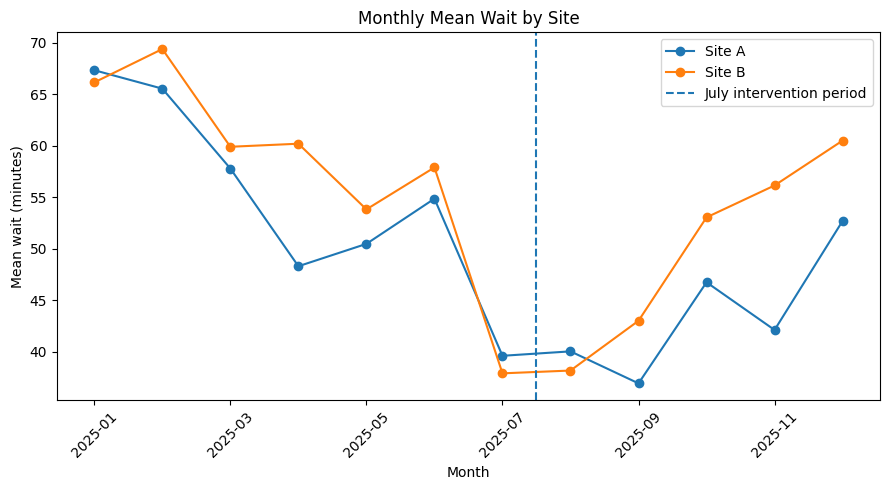

mean  median  count
site   period                          
Site A After   43.304754    32.0   1178
       Before  57.398464    45.0   1172
Site B After   48.377067    37.0    907
       Before  61.228695    44.0    927

In [4]:
monthly = V.groupby(['site','month']).wait_minutes.mean().unstack('site')
monthly.plot(marker='o', figsize=(9,5)); plt.axvline(6.5, linestyle='--', label='July intervention period'); plt.title('Monthly Mean Wait by Site'); plt.xlabel('Month'); plt.ylabel('Mean wait (minutes)'); plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); plt.show()
period = V.groupby(['site','period']).wait_minutes.agg(['mean','median','count'])
period

In [5]:
change_A = period.loc[('Site A','After'),'mean'] - period.loc[('Site A','Before'),'mean']
change_B = period.loc[('Site B','After'),'mean'] - period.loc[('Site B','Before'),'mean']
did = change_A - change_B
print('Site A change:', change_A, 'Site B change:', change_B, 'DiD:', did)

Site A change: -14.093710343788565 Site B change: -12.85162745944583 DiD: -1.2420828843427358


## Task 3 — Which departments improved?

The overall mean decreased by **13.58 minutes**. Department mean decreases are about -12.53 to 8.42 minutes (see table). This is not automatically suspicious: the overall mean is a weighted average, so it depends on department volume. Radiology's share grew from 16.25% to 26.33% and has the shortest waits; more Radiology visits can pull the overall mean downward. With pre-period department weights fixed, the overall change would be -10.16 minutes. The composition contribution is approximate, not a causal decomposition.

**Improved prompt:** *Normalize department labels and report how many records changed. For each department, show pre/post counts, shares, mean and median wait, and mean change. Show pooled overall mean change and also calculate a standardized comparison using pre-period department shares for both periods. Explain how changing department mix can influence the overall average. Do not imply all patients experienced the same improvement.*

In [6]:
dept_table = V.groupby(['dept_clean','period']).wait_minutes.agg(['mean','median','count'])
depart_shares = V.groupby(['period','dept_clean']).size().groupby(level=0).transform(lambda x: x/x.sum()*100)
depart_shares, dept_table

(period  dept_clean 
 After   Cardiology     14.868106
         Emergency      28.009592
         Orthopedics    13.333333
         Pediatrics     17.458034
         Radiology      26.330935
 Before  Cardiology     15.292997
         Emergency      32.396379
         Orthopedics    17.436875
         Pediatrics     18.627918
         Radiology      16.245831
 dtype: float64,
                          mean  median  count
 dept_clean  period                          
 Cardiology  After   45.567742    39.0    310
             Before  54.607477    45.0    321
 Emergency   After   66.368151    53.0    584
             Before  78.901471    65.0    680
 Orthopedics After   54.579137    46.0    278
             Before  64.377049    50.5    366
 Pediatrics  After   38.277473    30.0    364
             Before  46.693095    37.0    391
 Radiology   After   23.497268    19.0    549
             Before  32.343109    24.0    341)

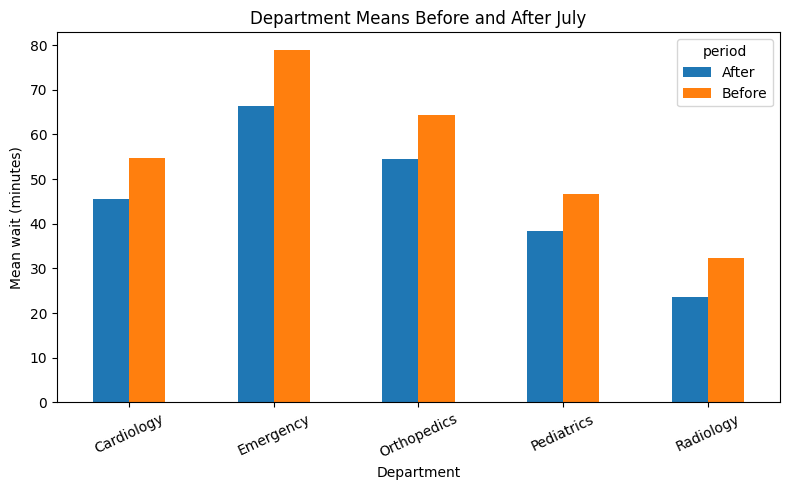

In [7]:
deptmeans = V.groupby(['dept_clean','period']).wait_minutes.mean().unstack()
deptmeans.plot(kind='bar', figsize=(8,5)); plt.title('Department Means Before and After July'); plt.ylabel('Mean wait (minutes)'); plt.xlabel('Department'); plt.xticks(rotation=25); plt.tight_layout(); plt.show()

## Task 4 — Does waiting reduce satisfaction?

Missing satisfaction is not just a small issue. For waits ≤90 minutes, 7.89% of scores are missing; for waits >90 minutes, 43.27% are missing. Long-wait patients are much more likely to have no score, so the available satisfaction average (**3.54**) may be too high to represent all patients. This is missing-not-at-random risk; we cannot determine the missing patients' satisfaction from this data alone. The observed correlation is -0.308 among rows with both values.

**Improved prompt:** *For valid visits, split waits at 90 minutes. For each group, report total n, nonmissing satisfaction n, missing n and missing percentage, observed satisfaction mean/median, and the wait–satisfaction correlation among complete cases. Explain how differential missingness—especially if longer-wait patients are less likely to respond—may bias the observed satisfaction results. Do not impute missing scores.*

In [8]:
sat_missing = V.groupby('wait_group').satisfaction.apply(lambda s: pd.Series({'n':len(s), 'missing_n':s.isna().sum(), 'missing_pct':s.isna().mean()*100, 'observed_mean':s.mean()}))
sat_missing

wait_group               
<=90        n                3664.000000
            missing_n         289.000000
            missing_pct         7.887555
            observed_mean       3.649185
>90         n                 520.000000
            missing_n         225.000000
            missing_pct        43.269231
            observed_mean       2.315254
Name: satisfaction, dtype: float64

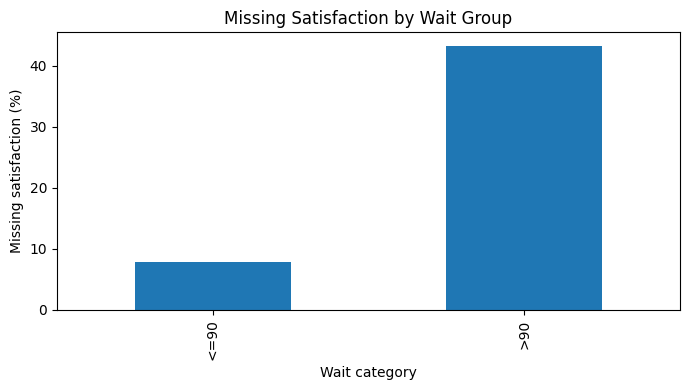

In [9]:
V.groupby('wait_group').satisfaction.apply(lambda x:x.isna().mean()*100).plot(kind='bar', figsize=(7,4)); plt.title('Missing Satisfaction by Wait Group'); plt.ylabel('Missing satisfaction (%)'); plt.xlabel('Wait category'); plt.tight_layout(); plt.show()

## Task 5 — The board headline

The prompt asks for a monthly two-site line chart, intervention marker, zero-based y-axis, and non-causal headline. It does not ask for distribution shape, medians, high-wait percentiles, sample-size labels per month, or uncertainty. Valid waits have mean **52.32**, median **39.00**, and 90th percentile **100.00 minutes**. The median better describes a typical visit; the 90th percentile captures the longer-wait experience. The maximum is 999 minutes. A mean-only chart hides variation and the long tail.

**Improved prompt:** *Create the requested monthly Site A/Site B line chart with a July 1 marker, zero y-axis, units and monthly sample sizes. Add a compact summary of mean, median, 90th percentile and maximum wait for valid rows, and discuss skew and outliers. Use association wording only and state limitations.*

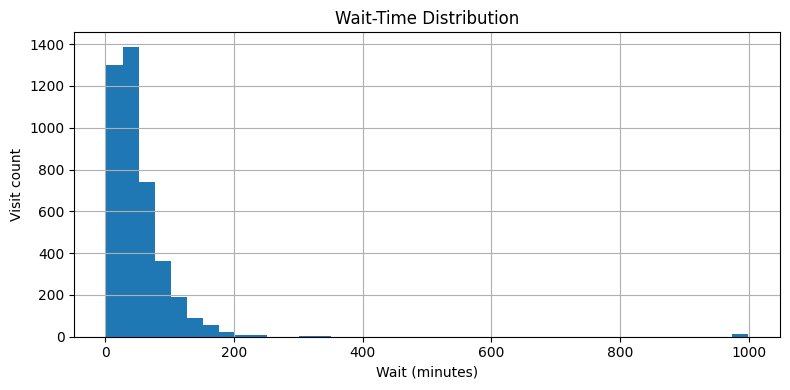

(mean      52.323375
 median    39.000000
 Name: wait_minutes, dtype: float64,
 np.float64(100.0),
 np.float64(999.0))

In [10]:
V.wait_minutes.hist(bins=40, figsize=(8,4)); plt.title('Wait-Time Distribution'); plt.xlabel('Wait (minutes)'); plt.ylabel('Visit count'); plt.tight_layout(); plt.show()
V.wait_minutes.agg(['mean','median']), V.wait_minutes.quantile(.9), V.wait_minutes.max()

## Task 6 — Do older patients wait longer?

Age and wait have almost no linear association (Pearson correlation **-0.009**). Median waits by age group are 0-17: 38.0, 18-39: 39.0, 40-64: 39.0, 65+: 40.0 minutes, which are similar. Triage level is much more associated with waiting: mean waits range from 14.76 minutes at level 1 to 76.18 at level 5. Higher-numbered levels have longer waits in this dataset. Average ages across triage levels are similar, so age does not appear to explain triage differences. This is descriptive, not proof of the reason for wait times.

**Improved prompt:** *Using valid visits, report age–wait correlation with a scatterplot or clear caveat about linear correlation. For age groups, show n, mean and median. Also report wait distributions by triage level and age distribution within triage levels. Avoid interpreting correlation as causation; explain whether age appears related to waits after considering triage descriptively.*

In [11]:
age_summary = V.groupby('age_group', observed=True).wait_minutes.agg(['mean','median','count'])
triage_summary = V.groupby('triage_level').wait_minutes.agg(['mean','median','count'])
print('Age group summary'); display(age_summary)
print('Triage summary'); display(triage_summary)
print('Age/wait Pearson correlation:', V.age.corr(V.wait_minutes))
V.groupby('triage_level').age.mean()

Age group summary


,mean,median,count
age_group,,,
0-17,53.751736,38.0,576
18-39,51.441636,39.0,1345
40-64,52.297912,39.0,1628
65+,52.960630,40.0,635


Triage summary


,mean,median,count
triage_level,,,
1,14.764706,8.0,170
2,26.861371,19.0,642
3,49.419025,38.0,1661
4,64.883305,54.0,1174
5,76.178771,62.0,537


Age/wait Pearson correlation: -0.009292015253058707


triage_level
1    42.505882
2    41.682243
3    41.645394
4    41.855196
5    43.137803
Name: age, dtype: float64

## Task 7 — Should we remove the outliers?

The IQR rule (Q1=22, Q3=65, IQR=43, upper fence=129.5) flags **189 visits** in this cleaning set. Most flagged visits are Emergency (128) and triage levels 4–5 (148). The distribution is strongly right-skewed (skew=9.89); an IQR flag means unusually high, not necessarily erroneous. The maximum wait is 999 minutes and 53 valid visits exceed 180 minutes. Excluding IQR outliers changes Site A's decrease to -10.42, Site B's to -5.16, and DiD to -5.26; it does not make a causal conclusion safe. The manual mentions 183 flags, but this explicit validity rule yields 189—a discrepancy to document rather than hide.

**Improved prompt:** *Calculate IQR fences on valid, unique visits. Report Q1/Q3/IQR/fences, flagged count, department and triage breakdown, maximum and >180-minute count. Inspect flags for plausible extreme values versus data errors; do not remove them without documented evidence. Compare Site A/B pre-post and DiD with and without flagged visits, including confidence intervals, and discuss right-skew.*

In [12]:
q1, q3 = V.wait_minutes.quantile([.25,.75]); iqr=q3-q1; lower=q1-1.5*iqr; upper=q3+1.5*iqr
outliers = V[(V.wait_minutes < lower) | (V.wait_minutes > upper)]
print({'Q1':q1,'Q3':q3,'IQR':iqr,'lower_fence':lower,'upper_fence':upper,'flagged_n':len(outliers)})
print('Department counts'); display(outliers.dept_clean.value_counts())
print('Triage counts'); display(outliers.triage_level.value_counts())
print('Max wait:', V.wait_minutes.max(), 'waits >180:', (V.wait_minutes>180).sum(), 'skew:', V.wait_minutes.skew())

{'Q1': 22.0, 'Q3': 65.0, 'IQR': 43.0, 'lower_fence': -42.5, 'upper_fence': 129.5, 'flagged_n': 189}
Department counts


dept_clean
Emergency      128
Orthopedics     34
Cardiology      16
Pediatrics       8
Radiology        3
Name: count, dtype: int64

Triage counts


triage_level
4    87
5    61
3    37
2     3
1     1
Name: count, dtype: int64

Max wait: 999.0 waits >180: 53 skew: 9.894712146731294


In [13]:
V_no_outliers = V[~V.index.isin(outliers.index)]
p = V_no_outliers.groupby(['site','period']).wait_minutes.mean()
change_A_noout = p['Site A','After']-p['Site A','Before']; change_B_noout=p['Site B','After']-p['Site B','Before']
print('Site A change, no IQR flags:',change_A_noout)
print('Site B change, no IQR flags:',change_B_noout)
print('DiD, no IQR flags:',change_A_noout-change_B_noout)

Site A change, no IQR flags: -10.420668585567846
Site B change, no IQR flags: -5.16403812071912
DiD, no IQR flags: -5.256630464848726


## Task 8 — Is the improvement statistically real?

A one-sided Welch t-test finds Site A's after-period mean lower than before (p=7.99e-09). Site B also shows a statistically significant decrease (p=0.000153), which cautions that a Site A before/after test may reflect wider trends. DiD = **-1.24 minutes** with bootstrap 95% CI **[-9.58, 7.43]**; this interval crosses zero. The department/triage-adjusted regression interaction is **0.86 minutes** (95% CI [-6.93, 8.66], p=0.828), also not statistically significant. Urgent (triage 1–2) shares differ and change over time, especially Site B, so patient mix can influence raw comparison. The board-safe conclusion: *Waits decreased at both sites after July 1, but the additional change at Site A was small and uncertain after comparison with Site B; this dataset alone does not establish that the new triage system caused the decrease.*

**Improved prompt:** *Use valid unique visits. Test Site A's before/after change using a Welch test and report effect size, 95% CI and p-value; repeat for Site B. Then estimate the DiD (Site A change minus Site B change) with a bootstrap 95% CI. Report urgent triage 1–2 shares by site/period. Fit an adjusted model controlling department and triage level and report its interaction estimate, CI and p-value. Distinguish statistical significance, practical size and causation; describe assumptions and limitations.*

In [14]:
# Welch tests and period changes
for site in ['Site A','Site B']:
    before=V[(V.site==site)& (V.period=='Before')].wait_minutes
    after=V[(V.site==site)& (V.period=='After')].wait_minutes
    print(site, 'change=',after.mean()-before.mean(), 'one-sided p=',stats.ttest_ind(after,before,equal_var=False,alternative='less').pvalue, 'two-sided p=',stats.ttest_ind(after,before,equal_var=False).pvalue)
print('DiD:',did)

Site A change= -14.093710343788565 one-sided p= 7.992474905294077e-09 two-sided p= 1.5984949810588154e-08
Site B change= -12.85162745944583 one-sided p= 0.00015334494840273973 two-sided p= 0.00030668989680547945
DiD: -1.2420828843427358


In [15]:
# Bootstrap DiD with 10,000 resamples, sampling within site-period groups
rng=np.random.default_rng(20261118); B=10000
samples={key:V[(V.site==key[0])&(V.period==key[1])].wait_minutes.to_numpy() for key in [('Site A','Before'),('Site A','After'),('Site B','Before'),('Site B','After')]}
boot=np.empty(B)
for i in range(B):
    m={key:rng.choice(x,size=len(x),replace=True).mean() for key,x in samples.items()}
    boot[i]=(m['Site A','After']-m['Site A','Before'])-(m['Site B','After']-m['Site B','Before'])
ci=np.quantile(boot,[.025,.975]); ci

array([-9.58292398,  7.43481576])

In [16]:
# Adjusted linear regression (descriptive adjustment): wait ~ site * after + department + triage
V['isA']=(V.site=='Site A').astype(int); V['after']=(V.period=='After').astype(int)
fit=ols('wait_minutes ~ isA*after + C(dept_clean) + C(triage_level)', data=V).fit()
print('Interaction estimate:',fit.params['isA:after'])
print('95% CI:',fit.conf_int().loc['isA:after'].tolist())
print('p-value:',fit.pvalues['isA:after'])

Interaction estimate: 0.8619123548044336
95% CI: [-6.931388140357408, 8.655212849966274]
p-value: 0.8283528268645469


## Overall conclusion and limitations

This dataset shows lower mean wait times after July 1 at both sites. Site A improved by about 14 minutes and Site B by about 13 minutes; the difference-in-differences estimate is small and its bootstrap confidence interval includes zero. Adjustment for department and triage level also does not show a clear additional Site A effect. Missing satisfaction scores are much more common among long waits, mixed date formats and duplicate IDs need cleaning, and unusually long waits should be investigated rather than automatically deleted. These are observational comparisons and cannot establish causality on their own.